# Введение

Демонстративная обработка сделана на данных реки __Эрдр__ (Франция), станции __NORT-SUR-ERDRE__.

В датасетах представлены суточные расходы воды (в м<sup>3</sup>/c) с указанием даты.

<font color="gray">Ежедневные данные о расходах воды // Global Runoff Data Centre (GRDC); обработка: студент ФГГТ НИУ ВШЭ Буторин Захар, [2026]. Условия использования: для учебных целей. Источник. URL: https://grdc.bafg.de/</font>

## Импорт библиотек

In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

grdc_file = "data/6123170_Q_Day.Cmd.txt"

## Выделение шапки "метаданных"

In [194]:
with open(grdc_file, encoding="cp1251", errors="replace") as f:
    lines =f.readlines() 

metadata = { } 

for line in lines:
    line = line.rstrip("\n")
    if line.strip().upper()=="# DATA": 
        break
    if line.startswith("#") and ":" in line:
        parts = line.lstrip("#").split(":", 1) 
        metadata[parts[0].strip().lower()]= parts[1].strip()
        
        
start_data = [line.strip().upper() for line in lines].index("# DATA")

for key in ["river", "station", "country", "latitude (dd)", "longitude (dd)",
            "altitude (m asl)", "catchment area (kmі)"]: 
    print(f"{key:>25}: {metadata.get(key,'-')}") 

print("Данные начинаются со строчки:",  start_data) 

                    river: ERDRE
                  station: NORT-SUR-ERDRE (MOULIN DE VAUX)
                  country: FR
            latitude (dd): 47.464394888
           longitude (dd): -1.48218338
         altitude (m asl): 4.47
     catchment area (kmі): 472.0
Данные начинаются со строчки: 35


## Определение разделителя и колонок

In [195]:
index_header = start_data + 1 
data_index = start_data + 2 

header_line = lines[index_header].rstrip()

if ";" in header_line:
    divid = ";"
    
elif "," in header_line: 
    divid = ","
    
elif "\t" in header_line:
    divid = "\t" 
    
else:
    divid = " "
    
columns = header_line.split(divid) 
 
    
print("Столбцы:", columns)

Столбцы: ['YYYY-MM-DD', 'hh:mm', ' Value']


## Загрузка данных, создание csv

In [196]:
new_dataset = pd.read_csv( 
    grdc_file,
    sep=divid,
    skiprows=data_index, 
    names=["date","time","Q"],
    engine="python",
    encoding="cp1251",
    
    na_values=["-999", "-999.000", "-999.0", ""],) 

new_dataset["date"] = pd.to_datetime(new_dataset["date"], errors="coerce")
new_dataset["Q"]= pd.to_numeric(new_dataset["Q"], errors="coerce")
new_dataset = new_dataset.dropna(subset=["date"]).reset_index(drop=True) 


new_dataset.to_csv("data/q_day_grdc.csv" , index=False)
new_dataset.head()

,date,time,Q
0,1991-01-01,--:--,3.019
1,1991-01-02,--:--,3.467
2,1991-01-03,--:--,6.488
3,1991-01-04,--:--,11.242
4,1991-01-05,--:--,16.978


## Сводка по временному ряду

In [197]:
print("Период", new_dataset["date"].min(), "по", new_dataset["date"].max())
print("Записей", len(new_dataset )) 
print("Пропусков Q", new_dataset["Q"].isna().sum())

Период 1991-01-01 00:00:00 по 2024-12-31 00:00:00
Записей 12419
Пропусков Q 374


## Фильтр за период 2000–2020

In [198]:
data20 = new_dataset[
    (new_dataset["date"] >= "2000-01-01") &
    (new_dataset["date"] <= "2020-12-31") 
].copy()

print("Период;", data20["date"].min(), "по", data20["date"].max()) 
print("Записей:", len(data20))
print("Пропускв Q:",  data20["Q"].isna().sum())

Период; 2000-01-01 00:00:00 по 2020-12-31 00:00:00
Записей: 7671
Пропускв Q: 0


## Гидрограф за 2000–2020

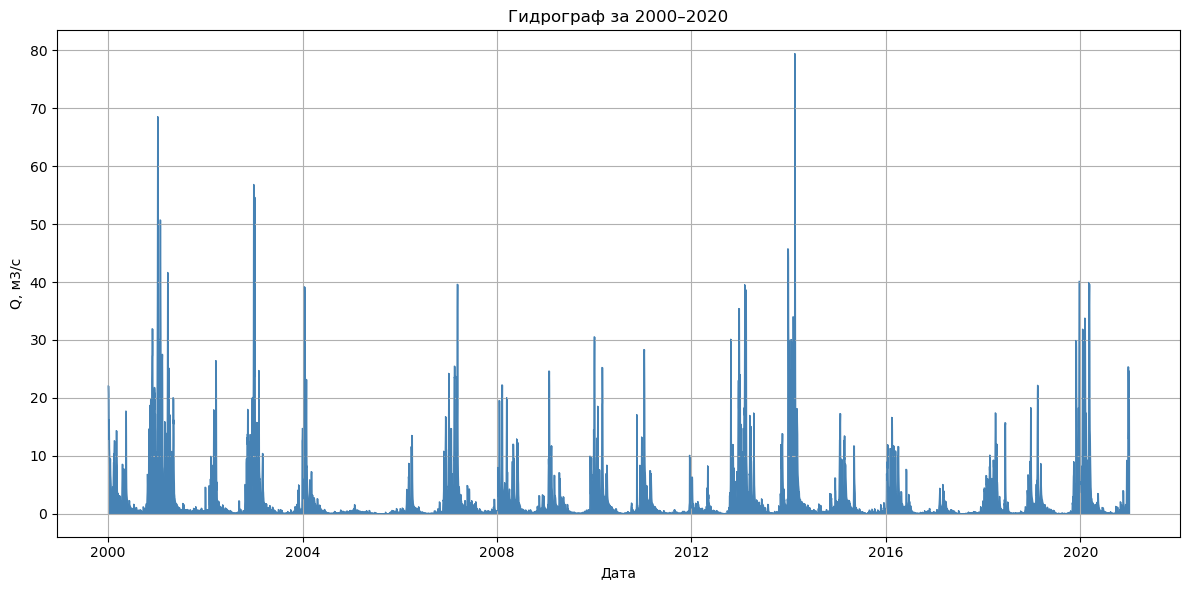

In [199]:
plt.figure(figsize=(12, 6)) 
plt.plot(data20["date"], data20["Q"], lw=0.6, color="steelblue")
plt.fill_between(data20["date"], data20["Q"], color="steelblue")

plt.title("Гидрограф за 2000–2020")  
plt.xlabel("Дата") 
plt.ylabel("Q, м3/с") 
plt.grid() 
plt.tight_layout()

plt.show()

## Среднемесячные значения

In [200]:
monthly = (
    data20
    .groupby([data20["date"].dt.year.rename("year"), 
              data20["date"].dt.month.rename("month")])["Q"]
    .mean()
    .reset_index(name="Q_mean" ))

monthly.head(12) 

,year,month,Q_mean
0,2000,1,8.184194
1,2000,2,6.569931
2,2000,3,4.210613
3,2000,4,3.954933
4,2000,5,4.003355
5,2000,6,1.189733
6,2000,7,0.896548
7,2000,8,0.528290
8,2000,9,0.544800
9,2000,10,2.421484


## Минимум и максимум расхода

In [201]:
q_min = monthly["Q_mean"].min()
q_max = monthly["Q_mean"].max() 
 
print(f"Минимум  {q_min:.3f} м3/с") 
print(f"Максимум {q_max:.3f} м3/с")

Минимум  0.011 м3/с
Максимум 24.906 м3/с


## Среднемноголетний расход по месяцам

In [202]:
column_table = (
    monthly
    .groupby("month")["Q_mean"]
    .mean()
    .reset_index(name="Q_clim")
)

monthes_name = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
                "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]

column_table["name"] = column_table["month"].map(lambda m: monthes_name[m-1])

print(column_table[["month", "name", "Q_clim"]].to_string(index=False))

 month name   Q_clim
     1  Янв 7.444610
     2  Фев 6.757525
     3  Мар 5.150140
     4  Апр 2.387949
     5  Май 1.598581
     6  Июн 0.909506
     7  Июл 0.384478
     8  Авг 0.234553
     9  Сен 0.235927
    10  Окт 0.735939
    11  Ноя 2.646081
    12  Дек 5.300157


## Среднегодовые расходы и среднее между годами

In [203]:
year_average =(
    data20
    .groupby(data20["date"].dt.year.rename("year"))["Q"]
    .mean()
    .reset_index(name="Q_mean_annual" )
)

print("Лет в ряду:", len(year_average))
print(year_average)

mean_year = year_average["Q_mean_annual"].mean()

print(f"Средний годовой расход за 2000–2020 {mean_year:.3f} м3/с")

Лет в ряду: 21
    year  Q_mean_annual
0   2000       5.024833
1   2001       5.648844
2   2002       3.463975
3   2003       2.533967
4   2004       2.004689
5   2005       0.290266
6   2006       1.582627
7   2007       3.112208
8   2008       2.772883
9   2009       2.250227
10  2010       2.602247
11  2011       1.437540
12  2012       2.609719
13  2013       4.512367
14  2014       4.670671
15  2015       1.860326
16  2016       2.187582
17  2017       0.568271
18  2018       2.670721
19  2019       2.864397
20  2020       4.120347
Средний годовой расход за 2000–2020 2.799 м3/с


## Трендовое сравнение за период

In [207]:
x = year_average["year"].values.astype(float) 
y = year_average["Q_mean_annual"].values
 
k = ((x - x.mean())*(y - y.mean())).sum() / ((x - x.mean())**2).sum()
b = y.mean()-k*x.mean() 

print(f"Уравнение тренда Q  {k:+.4f}·year + {b:.2f}")
print(f"Скорость изменений {k:+.4f} м3/с за год")

print(f"За 2000–2020: {k * 20:+.3f} м3/с")

Уравнение тренда Q  -0.0388·year + 80.72
Скорость изменений -0.0388 м3/с за год
За 2000–2020: -0.775 м3/с
